# LAB | Imbalanced Data — Completed Solution

## Credit Card Fraud Detection

This notebook investigates an imbalanced binary-classification problem and compares four Logistic Regression approaches:

1. Original imbalanced training data (baseline)
2. Random oversampling
3. Random undersampling
4. SMOTE

The target is **fraud**: `0 = legitimate transaction`, `1 = fraudulent transaction`.

> **Important:** The train/test split is performed before resampling. Only the training data is resampled, so the untouched test set remains representative of real-world class proportions and data leakage is avoided.

## 1. Load the data

Data source: `https://raw.githubusercontent.com/data-bootcamp-v4/data/main/card_transdata.csv`

### Feature metadata

- **distance_from_home:** Distance from home where the transaction occurred.
- **distance_from_last_transaction:** Distance from the location of the previous transaction.
- **ratio_to_median_purchase_price:** Transaction price divided by the customer's median purchase price.
- **repeat_retailer:** Whether the transaction occurred at a previously used retailer.
- **used_chip:** Whether the card chip was used.
- **used_pin_number:** Whether a PIN was used.
- **online_order:** Whether the transaction was an online order.
- **fraud:** Target variable (`0 = legitimate`, `1 = fraud`).

In [1]:
# Core libraries
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    average_precision_score, roc_auc_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)

from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", palette="colorblind")

In [2]:
url = "https://raw.githubusercontent.com/data-bootcamp-v4/data/main/card_transdata.csv"
fraud = pd.read_csv(url)

print(f"Dataset shape: {fraud.shape}")
display(fraud.head())
display(fraud.info())
print(f"Total missing values: {fraud.isna().sum().sum()}")

Dataset shape: (1000000, 8)


,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order,fraud
0,57.877857,0.311140,1.945940,1.0,1.0,0.0,0.0,0.0
1,10.829943,0.175592,1.294219,1.0,0.0,0.0,0.0,0.0
2,5.091079,0.805153,0.427715,1.0,0.0,0.0,1.0,0.0
3,2.247564,5.600044,0.362663,1.0,1.0,0.0,1.0,0.0
4,44.190936,0.566486,2.222767,1.0,1.0,0.0,1.0,0.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 8 columns):
 #   Column                          Non-Null Count    Dtype  
---  ------                          --------------    -----  
 0   distance_from_home              1000000 non-null  float64
 1   distance_from_last_transaction  1000000 non-null  float64
 2   ratio_to_median_purchase_price  1000000 non-null  float64
 3   repeat_retailer                 1000000 non-null  float64
 4   used_chip                       1000000 non-null  float64
 5   used_pin_number                 1000000 non-null  float64
 6   online_order                    1000000 non-null  float64
 7   fraud                           1000000 non-null  float64
dtypes: float64(8)
memory usage: 61.0 MB


None

Total missing values: 0


## 2. Target distribution

For fraud detection, the positive class (`fraud = 1`) is the class of greatest practical importance. Accuracy alone can be misleading because a model that predicts every transaction as legitimate would already score very highly. Therefore, the main metrics used below are:

- **Recall (fraud):** Of all actual fraud cases, how many did the model detect?
- **Precision (fraud):** Of all transactions flagged as fraud, how many were truly fraud?
- **F1-score (fraud):** Harmonic balance between fraud precision and fraud recall.
- **PR-AUC:** Ranking performance focused on the positive/minority class; particularly informative for imbalanced data.
- **ROC-AUC:** Overall ability to rank fraud above legitimate transactions across thresholds.

,Count,Percentage
Legitimate (0),912597,91.26
Fraud (1),87403,8.74


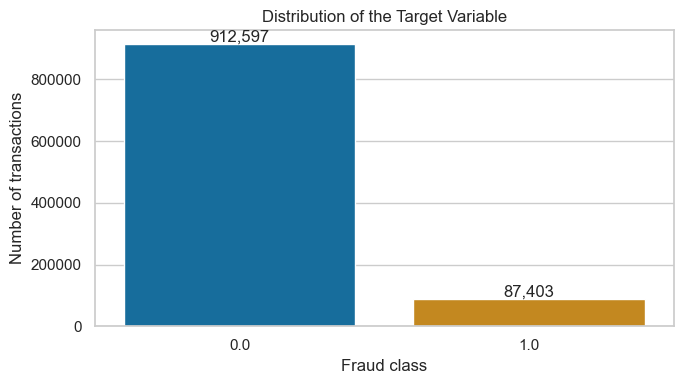

Fraud represents only 8.74% of all transactions.
Conclusion: Yes, this is an imbalanced dataset because the legitimate class strongly outnumbers the fraud class.


In [3]:
target_counts = fraud["fraud"].value_counts().sort_index()
target_percent = fraud["fraud"].value_counts(normalize=True).sort_index().mul(100)

distribution = pd.DataFrame({
    "Count": target_counts.astype(int),
    "Percentage": target_percent.round(2)
})
distribution.index = ["Legitimate (0)", "Fraud (1)"]
display(distribution)

fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(data=fraud, x="fraud", hue="fraud", legend=False, ax=ax)
ax.set(title="Distribution of the Target Variable", xlabel="Fraud class", ylabel="Number of transactions")
for container in ax.containers:
    ax.bar_label(container, fmt="{:,.0f}")
plt.tight_layout()
plt.show()

minority_pct = target_percent.loc[1.0]
print(f"Fraud represents only {minority_pct:.2f}% of all transactions.")
print("Conclusion: Yes, this is an imbalanced dataset because the legitimate class strongly outnumbers the fraud class.")

## 3. Train/test split

`stratify=y` preserves approximately the same fraud proportion in the training and test sets. The test set is never resampled.

In [4]:
X = fraud.drop(columns="fraud")
y = fraud["fraud"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape: ", X_test.shape)
print(f"Training fraud rate: {y_train.mean():.2%}")
print(f"Test fraud rate:     {y_test.mean():.2%}")

X_train shape: (800000, 7)
X_test shape:  (200000, 7)
Training fraud rate: 8.74%
Test fraud rate:     8.74%


## 4. Evaluation helper

All four methods use the same scaled Logistic Regression model and the same untouched test set, making their results directly comparable. Scaling is fitted only on each model's training data.

In [5]:
results = []
predictions = {}

def train_and_evaluate(name, X_fit, y_fit):
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("logistic_regression", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
    ])
    model.fit(X_fit, y_fit)

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    predictions[name] = y_pred

    metrics = {
        "Method": name,
        "Train rows": len(y_fit),
        "Accuracy": accuracy_score(y_test, y_pred),
        "Fraud precision": precision_score(y_test, y_pred, zero_division=0),
        "Fraud recall": recall_score(y_test, y_pred, zero_division=0),
        "Fraud F1": f1_score(y_test, y_pred, zero_division=0),
        "PR-AUC": average_precision_score(y_test, y_prob),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    }
    results.append(metrics)

    print(f"{name} — training distribution")
    print(pd.Series(y_fit).value_counts().sort_index())
    print()
    print("Classification report on untouched test data:")
    print(classification_report(y_test, y_pred, target_names=["Legitimate", "Fraud"], digits=4))

    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred,
        display_labels=["Legitimate", "Fraud"],
        cmap="Blues", values_format=",d"
    )
    plt.title(f"Confusion Matrix — {name}")
    plt.grid(False)
    plt.tight_layout()
    plt.show()
    return model


## 5. Baseline Logistic Regression

The baseline is trained on the original imbalanced training set without changing class proportions.

Original data — training distribution
fraud
0    730078
1     69922
Name: count, dtype: int64

Classification report on untouched test data:
              precision    recall  f1-score   support

  Legitimate     0.9634    0.9933    0.9781    182519
       Fraud     0.8964    0.6056    0.7228     17481

    accuracy                         0.9594    200000
   macro avg     0.9299    0.7994    0.8505    200000
weighted avg     0.9575    0.9594    0.9558    200000



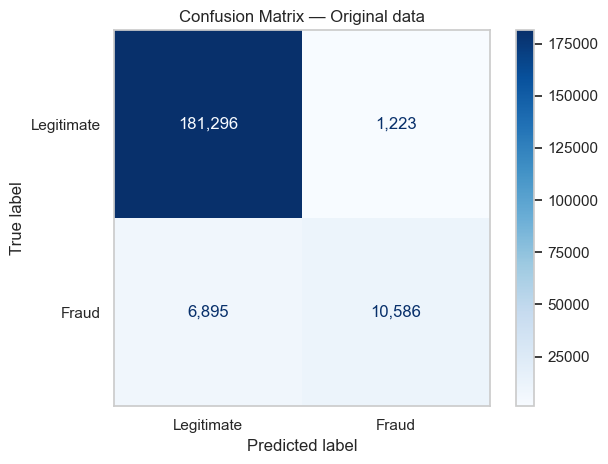

In [6]:
baseline_model = train_and_evaluate("Original data", X_train, y_train)

## 6. Random oversampling

Random oversampling balances the training data by duplicating minority-class observations. It retains all majority-class observations, but repeated minority examples can increase overfitting risk.

Random oversampling — training distribution
fraud
0    730078
1    730078
Name: count, dtype: int64

Classification report on untouched test data:
              precision    recall  f1-score   support

  Legitimate     0.9947    0.9335    0.9631    182519
       Fraud     0.5773    0.9478    0.7176     17481

    accuracy                         0.9348    200000
   macro avg     0.7860    0.9407    0.8403    200000
weighted avg     0.9582    0.9348    0.9417    200000



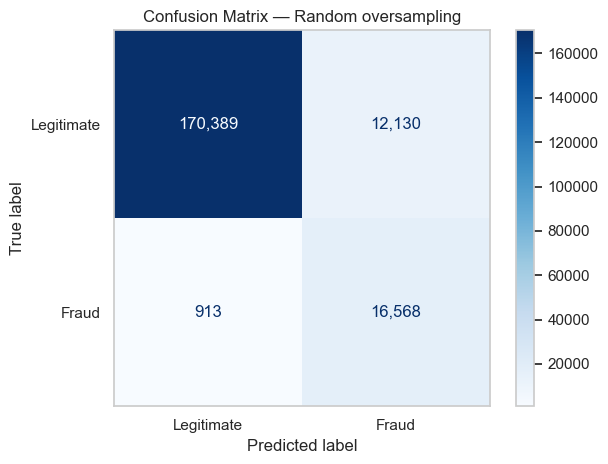

In [7]:
oversampler = RandomOverSampler(random_state=RANDOM_STATE)
X_train_over, y_train_over = oversampler.fit_resample(X_train, y_train)
oversample_model = train_and_evaluate("Random oversampling", X_train_over, y_train_over)

## 7. Random undersampling

Random undersampling balances the training data by discarding randomly selected majority-class observations. It is computationally efficient, but it may lose useful information about legitimate transactions.

Random undersampling — training distribution
fraud
0    69922
1    69922
Name: count, dtype: int64

Classification report on untouched test data:
              precision    recall  f1-score   support

  Legitimate     0.9946    0.9336    0.9631    182519
       Fraud     0.5773    0.9475    0.7174     17481

    accuracy                         0.9348    200000
   macro avg     0.7860    0.9405    0.8403    200000
weighted avg     0.9582    0.9348    0.9417    200000



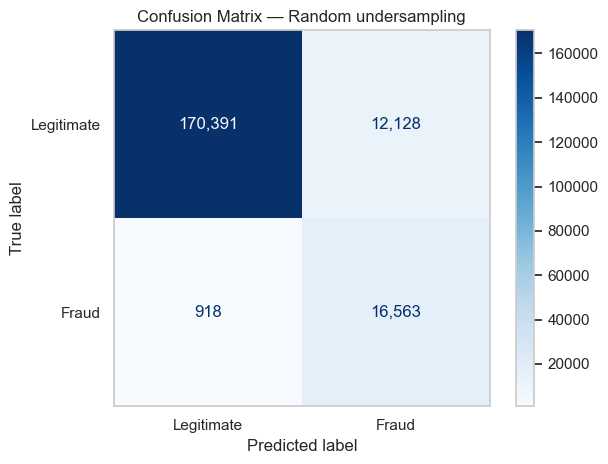

In [8]:
undersampler = RandomUnderSampler(random_state=RANDOM_STATE)
X_train_under, y_train_under = undersampler.fit_resample(X_train, y_train)
undersample_model = train_and_evaluate("Random undersampling", X_train_under, y_train_under)

## 8. SMOTE

SMOTE balances the training data by creating synthetic minority-class observations between nearby fraud examples rather than simply duplicating existing rows.

SMOTE — training distribution
fraud
0    730078
1    730078
Name: count, dtype: int64

Classification report on untouched test data:
              precision    recall  f1-score   support

  Legitimate     0.9945    0.9341    0.9634    182519
       Fraud     0.5790    0.9462    0.7184     17481

    accuracy                         0.9352    200000
   macro avg     0.7868    0.9402    0.8409    200000
weighted avg     0.9582    0.9352    0.9420    200000



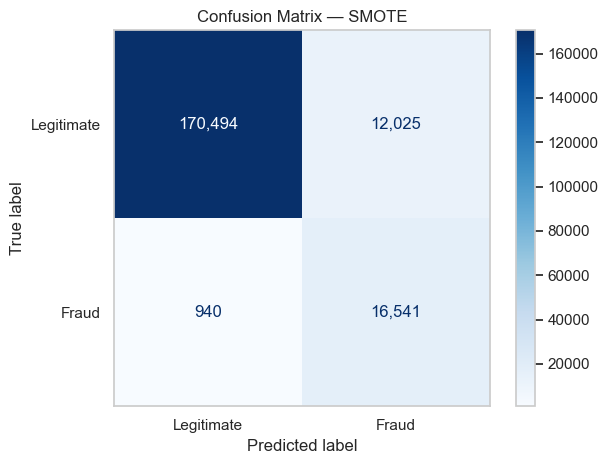

In [9]:
smote = SMOTE(random_state=RANDOM_STATE)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)
smote_model = train_and_evaluate("SMOTE", X_train_smote, y_train_smote)

## 9. Compare all approaches

,Train rows,Accuracy,Fraud precision,Fraud recall,Fraud F1,PR-AUC,ROC-AUC
Method,,,,,,,
Original data,"800,000",0.959410,0.896435,0.605572,0.722841,0.807224,0.966977
Random oversampling,"1,460,156",0.934785,0.577322,0.947772,0.717556,0.757315,0.979530
Random undersampling,"139,844",0.934770,0.577289,0.947486,0.717448,0.756823,0.979561
SMOTE,"1,460,156",0.935175,0.579045,0.946227,0.718440,0.761676,0.979175


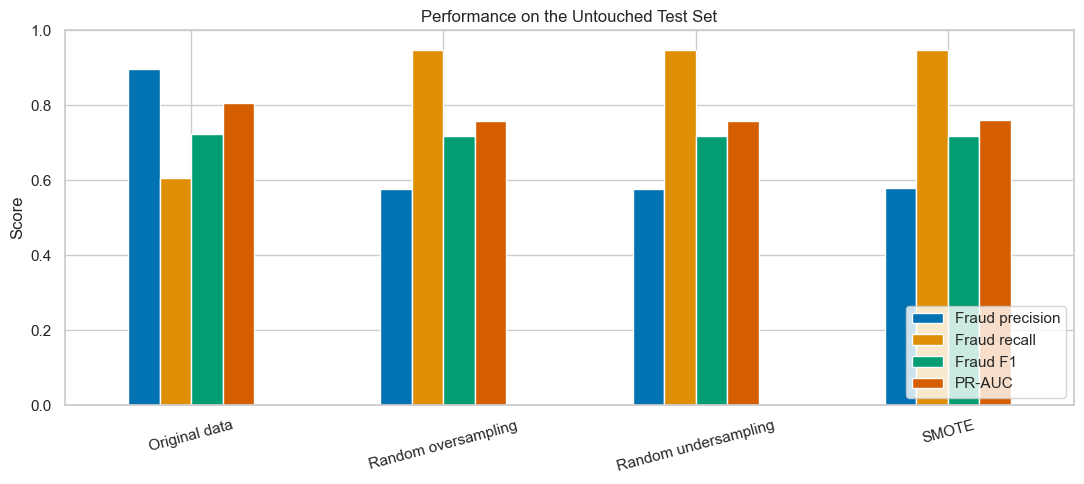

In [10]:
comparison = pd.DataFrame(results).set_index("Method")
metric_columns = ["Accuracy", "Fraud precision", "Fraud recall", "Fraud F1", "PR-AUC", "ROC-AUC"]
display(comparison.style.format({col: "{:.4f}" for col in metric_columns}).format({"Train rows": "{:,.0f}"}))

plot_data = comparison[["Fraud precision", "Fraud recall", "Fraud F1", "PR-AUC"]]
ax = plot_data.plot(kind="bar", figsize=(11, 5), ylim=(0, 1), rot=15)
ax.set(title="Performance on the Untouched Test Set", ylabel="Score", xlabel="")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [11]:
# Direct comparison with the original-data baseline
baseline = comparison.loc["Original data"]
improvement = comparison.copy()
for col in metric_columns:
    improvement[col] = comparison[col] - baseline[col]

display(improvement[metric_columns].style.format("{:+.4f}"))

best_f1 = comparison["Fraud F1"].idxmax()
best_recall = comparison["Fraud recall"].idxmax()
best_pr_auc = comparison["PR-AUC"].idxmax()

print(f"Highest fraud F1-score: {best_f1} ({comparison.loc[best_f1, 'Fraud F1']:.4f})")
print(f"Highest fraud recall:   {best_recall} ({comparison.loc[best_recall, 'Fraud recall']:.4f})")
print(f"Highest PR-AUC:         {best_pr_auc} ({comparison.loc[best_pr_auc, 'PR-AUC']:.4f})")

,Accuracy,Fraud precision,Fraud recall,Fraud F1,PR-AUC,ROC-AUC
Method,,,,,,
Original data,+0.0000,+0.0000,+0.0000,+0.0000,+0.0000,+0.0000
Random oversampling,-0.0246,-0.3191,+0.3422,-0.0053,-0.0499,+0.0126
Random undersampling,-0.0246,-0.3191,+0.3419,-0.0054,-0.0504,+0.0126
SMOTE,-0.0242,-0.3174,+0.3407,-0.0044,-0.0455,+0.0122


Highest fraud F1-score: Original data (0.7228)
Highest fraud recall:   Random oversampling (0.9478)
Highest PR-AUC:         Original data (0.8072)


## 10. Conclusions

- The dataset is **imbalanced**: fraud makes up only about 8.74% of all observations.
- Accuracy is reported, but it is not the deciding metric. Fraud **recall**, **precision**, **F1-score**, and **PR-AUC** are more informative.
- Resampling changes the trade-off between false negatives and false positives. A higher fraud recall means fewer real fraud cases are missed, while a lower precision means more legitimate transactions may be incorrectly flagged.
- **Random oversampling** and **SMOTE** usually improve minority-class recall because the model receives a balanced training signal. SMOTE differs by synthesizing new minority observations.
- **Random undersampling** can also improve recall, but it discards many legitimate observations and may lose useful information.
- The best method should be selected according to the business cost of errors. In fraud detection, a false negative (missed fraud) is often more costly than a false positive (a legitimate transaction sent for review), so a recall-oriented choice may be justified.

The printed comparison above identifies the empirical winner for fraud F1, fraud recall, and PR-AUC. This is preferable to choosing a method based on accuracy alone.